<a href="https://colab.research.google.com/github/Muredepadure/adversarial-ml-evasion/blob/main/PGDPractice.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
GPU available: True
GPU name: Tesla T4


In [ ]:
!pip install adversarial-robustness-toolbox

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 55.4 MB/s eta 0:00:00


In [ ]:
import torch, torch.nn as nn, torch.nn.functional as F
from torchvision import datasets, transforms

device = torch.device("cuda")
tfm = transforms.ToTensor()  # pixels scaled to [0,1]

train = datasets.MNIST(root="./data", train=True,  download=True, transform=tfm)
test  = datasets.MNIST(root="./data", train=False, download=True, transform=tfm)
train_loader = torch.utils.data.DataLoader(train, batch_size=128, shuffle=True)
test_loader  = torch.utils.data.DataLoader(test,  batch_size=256)
print("train:", len(train), " test:", len(test))

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.38MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 129kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.22MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 13.7MB/s]

train: 60000  test: 10000


In [ ]:
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, 3, 1)
        self.conv2 = nn.Conv2d(32, 64, 3, 1)
        self.fc1 = nn.Linear(9216, 128)
        self.fc2 = nn.Linear(128, 10)
    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.max_pool2d(F.relu(self.conv2(x)), 2)
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)        # raw logits (no softmax)

model = Net().to(device)
print(model)

Net(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
  (fc1): Linear(in_features=9216, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [ ]:
opt = torch.optim.Adam(model.parameters(), lr=1e-3)

model.train()
for epoch in range(2):                         # 2 passes is enough for ~99%
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        opt.zero_grad()
        loss = F.cross_entropy(model(x), y)
        loss.backward()
        opt.step()
    print(f"epoch {epoch+1} done, last batch loss {loss.item():.4f}")

epoch 1 done, last batch loss 0.0318
epoch 2 done, last batch loss 0.0071


In [ ]:
model.eval()
correct = total = 0
with torch.no_grad():
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        pred = model(x).argmax(1)
        correct += (pred == y).sum().item()
        total += y.size(0)
print(f"clean test accuracy: {100*correct/total:.2f}%")

clean test accuracy: 98.53%


In [ ]:
def pgd_attack(model, images, labels, eps=0.3, alpha=0.01, iters=40):
    images, labels = images.to(device), labels.to(device)
    ori = images.clone().detach()                 # remember the original

    # start from a random point inside the eps-ball
    adv = ori + torch.empty_like(ori).uniform_(-eps, eps)
    adv = torch.clamp(adv, 0, 1).detach()

    for i in range(iters):
        adv.requires_grad_(True)
        loss = F.cross_entropy(model(adv), labels)   # loss w.r.t. CURRENT adv
        grad = torch.autograd.grad(loss, adv)[0]     # gradient of loss w.r.t. input

        # ---- YOUR LINE: take one gradient-ASCENT step of size alpha ----
        # push adv in the direction that INCREASES the loss, using the sign of grad
        adv = adv.detach() + torch.sign(grad) * alpha

        # project back into the eps-ball around the original, then to valid pixels
        adv = torch.min(torch.max(adv, ori - eps), ori + eps)
        adv = torch.clamp(adv, 0, 1).detach()

    return adv

In [ ]:
# grab one batch of clean test images
x, y = next(iter(test_loader))
x, y = x.to(device), y.to(device)

# clean accuracy on this batch
model.eval()
clean_pred = model(x).argmax(1)
clean_acc = (clean_pred == y).float().mean().item()

# craft adversarial versions and re-measure
x_adv = pgd_attack(model, x, y, eps=0.3, alpha=0.01, iters=40)
adv_pred = model(x_adv).argmax(1)
adv_acc = (adv_pred == y).float().mean().item()

print(f"clean accuracy on this batch: {100*clean_acc:.2f}%")
print(f"accuracy after PGD attack:    {100*adv_acc:.2f}%")

clean accuracy on this batch: 100.00%
accuracy after PGD attack:    0.00%


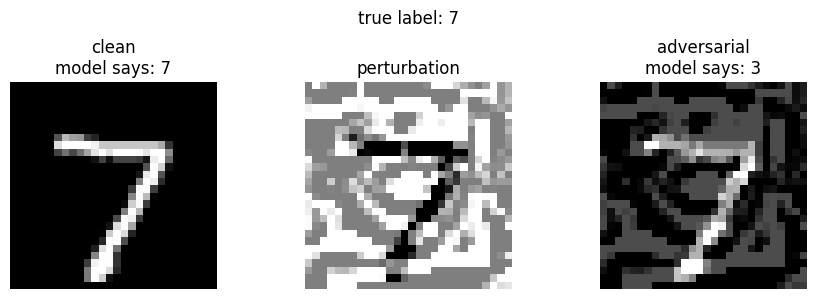

In [ ]:
import matplotlib.pyplot as plt

# pick the first image in the batch
i = 0
clean_img = x[i, 0].detach().cpu()
adv_img   = x_adv[i, 0].detach().cpu()
pert      = (adv_img - clean_img)

true_label  = y[i].item()
clean_guess = model(x[i:i+1]).argmax(1).item()
adv_guess   = model(x_adv[i:i+1]).argmax(1).item()

fig, ax = plt.subplots(1, 3, figsize=(9, 3))
ax[0].imshow(clean_img, cmap="gray");          ax[0].set_title(f"clean\nmodel says: {clean_guess}")
ax[1].imshow(pert, cmap="gray");               ax[1].set_title("perturbation")
ax[2].imshow(adv_img, cmap="gray");            ax[2].set_title(f"adversarial\nmodel says: {adv_guess}")
for a in ax: a.axis("off")
plt.suptitle(f"true label: {true_label}")
plt.tight_layout(); plt.show()